# Deep Learning for Perception — Assignment 2
## Section B: Robust Classification with Limited Data (CIFAR-10)

**Roll No:** 23F-0600

**Goal:** train an Inception-style CNN from scratch on only 500 CIFAR-10 images (50 per class) and make it robust to a shifted test set (rotation, brightness/contrast, blur, noise, occlusion + one hidden corruption).

**Rules followed:** no pretrained weights · ≤ 1,000,000 trainable parameters · at least one Inception module · 400/100 train/val split, all choices made on validation only · on-the-fly augmentation on training data only · max 60 epochs · 3 seeds, results reported as mean ± std.

**Run on Kaggle or Google Colab:** Accelerator = GPU, Internet = ON (CIFAR-10 is downloaded by `cifar10.load_data()`). Then *Run All*.

### Environment Setup
Import the libraries used in this notebook and check that the GPU is available.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # hide TensorFlow's C++ log lines (set before importing TF)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Set and report the random seeds. Every training run is repeated with 3 seeds.

In [2]:
SEEDS = [42, 123, 2026]   # 3 training seeds -> every result is reported as mean ± std
DATA_SEED = 42            # fixed seed for picking the 500 images and the 400/100 split
SHIFT_SEED = 1234         # fixed seed for the shifted-test corruption pipeline
EPOCHS = 60               # maximum allowed by the rules
BATCH_SIZE = 32

def set_seed(seed):
    keras.utils.set_random_seed(seed)   # sets Python, NumPy and TensorFlow seeds together

tf.config.experimental.enable_op_determinism()   # same seed -> same numbers on every run
set_seed(DATA_SEED)

print("Training seeds:", SEEDS)
print("Data seed:", DATA_SEED, "| Shift seed:", SHIFT_SEED)

Training seeds: [42, 123, 2026]
Data seed: 42 | Shift seed: 1234


### Data Preparation
Load the built-in CIFAR-10 dataset and normalize pixels to the 0–1 range.

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

# Labels come as (N, 1) -> flatten to (N,)
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

# Normalize pixels to the 0-1 range
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Full train set:", X_train_full.shape)
print("Test set:", X_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2574s 15us/step
Full train set: (50000, 32, 32, 3)
Test set: (10000, 32, 32, 3)


Build `train_small`: 50 images per class (500 total) selected with a fixed seed.

In [4]:
rng = np.random.default_rng(DATA_SEED)

small_idx = []
for c in range(10):
    class_idx = np.where(y_train_full == c)[0]
    small_idx.extend(rng.choice(class_idx, 50, replace=False))
small_idx = np.array(small_idx)

X_small = X_train_full[small_idx]
y_small = y_train_full[small_idx]

print("train_small shape:", X_small.shape)
print("Images per class:", np.bincount(y_small))

train_small shape: (500, 32, 32, 3)
Images per class: [50 50 50 50 50 50 50 50 50 50]


Split `train_small` into 400 training and 100 validation images (stratified, 40/10 per class).

In [5]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_small, y_small, test_size=100, random_state=DATA_SEED, stratify=y_small
)

# One-hot labels (needed for label smoothing and Mixup later)
y_tr_oh = to_categorical(y_tr, 10).astype('float32')
y_val_oh = to_categorical(y_val, 10).astype('float32')

print("Train:", X_tr.shape, "| per class:", np.bincount(y_tr))
print("Val:  ", X_val.shape, "| per class:", np.bincount(y_val))

Train: (400, 32, 32, 3) | per class: [40 40 40 40 40 40 40 40 40 40]
Val:   (100, 32, 32, 3) | per class: [10 10 10 10 10 10 10 10 10 10]


Display two training images from each class.

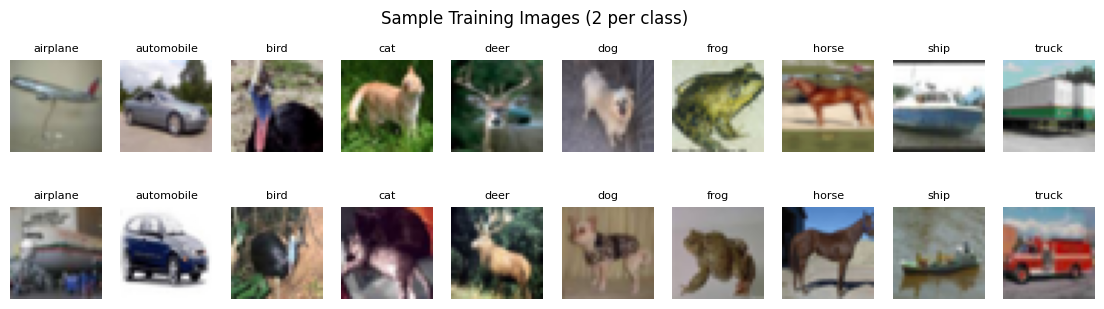

In [6]:
plt.figure(figsize=(14, 3.5))
for c in range(10):
    for j in range(2):
        plt.subplot(2, 10, j * 10 + c + 1)
        plt.imshow(X_tr[y_tr == c][j])
        plt.title(class_names[c], fontsize=8)
        plt.axis('off')
plt.suptitle("Sample Training Images (2 per class)")
plt.show()

### Building the Shifted Test Set
The assignment's `shifted_test` is CIFAR-10 test images passed through a fixed, seeded corruption pipeline. It is built here once with `SHIFT_SEED` and is **never** used for training or tuning.

Corruption functions for the listed shifts: rotation, brightness/contrast, blur, noise and a 16×16 occlusion (25% of the image).

In [7]:
def rotate(img, angle):
    return ndimage.rotate(img, angle, reshape=False, order=1, mode='nearest')

def brightness_contrast(img, brightness, contrast):
    mean = img.mean()
    return (img - mean) * contrast + mean + brightness

def blur(img, sigma):
    return ndimage.gaussian_filter(img, sigma=(sigma, sigma, 0))

def add_noise(img, std, rng):
    return img + rng.normal(0, std, img.shape)

def occlude(img, y0, x0, value, size=16):
    img = img.copy()
    img[y0:y0 + size, x0:x0 + size, :] = value   # 16x16 patch = 25% of a 32x32 image
    return img

The hidden corruption (not listed in the assignment and **not** used in training augmentation): random RGB channel swap.

In [8]:
CHANNEL_PERMS = [[0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]

def channel_swap(img, perm):
    return img[:, :, perm]

Apply all corruptions to one image and record the parameters that were used.

In [9]:
def make_shifted(img, rng):
    info = {}
    info['angle'] = rng.uniform(-25, 25)
    info['brightness'] = rng.uniform(-0.3, 0.3)
    info['contrast'] = rng.uniform(0.5, 1.5)
    info['blur'] = rng.uniform(0.5, 1.2) if rng.random() < 0.5 else 0.0
    info['noise'] = rng.uniform(0.02, 0.08) if rng.random() < 0.5 else 0.0
    info['occ_y'] = rng.integers(0, 17)
    info['occ_x'] = rng.integers(0, 17)
    occ_value = rng.uniform(0, 1)
    info['swapped'] = rng.random() < 0.5
    perm = CHANNEL_PERMS[rng.integers(0, 5)]

    img = rotate(img, info['angle'])
    img = brightness_contrast(img, info['brightness'], info['contrast'])
    if info['blur'] > 0:
        img = blur(img, info['blur'])
    if info['noise'] > 0:
        img = add_noise(img, info['noise'], rng)
    img = occlude(img, info['occ_y'], info['occ_x'], occ_value)
    if info['swapped']:
        img = channel_swap(img, perm)
    return np.clip(img, 0, 1), info

Generate `shifted_test` (10,000 images) with the fixed seed. `clean_test` is the original test set.

In [10]:
rng_shift = np.random.default_rng(SHIFT_SEED)

shifted_imgs, shifted_info = [], []
for img in X_test:
    new_img, info = make_shifted(img, rng_shift)
    shifted_imgs.append(new_img)
    shifted_info.append(info)

X_clean = X_test
X_shifted = np.array(shifted_imgs, dtype='float32')
shift_info = pd.DataFrame(shifted_info)

print("clean_test:", X_clean.shape)
print("shifted_test:", X_shifted.shape)
shift_info.head()

clean_test: (10000, 32, 32, 3)
shifted_test: (10000, 32, 32, 3)


,angle,brightness,contrast,blur,noise,occ_y,occ_x,swapped
0,23.834988,-0.071883,1.423246,0.723368,0.034506,13,5,True
1,-16.320385,-0.191474,0.940514,1.155018,0.075167,7,0,False
2,7.471004,-0.098216,1.086070,0.998663,0.050986,16,16,False
3,-7.682053,0.185250,0.866222,0.000000,0.027947,2,3,True
4,-22.152713,-0.211162,0.758820,0.876827,0.064044,3,3,True


Compare clean and shifted versions of the same test images.

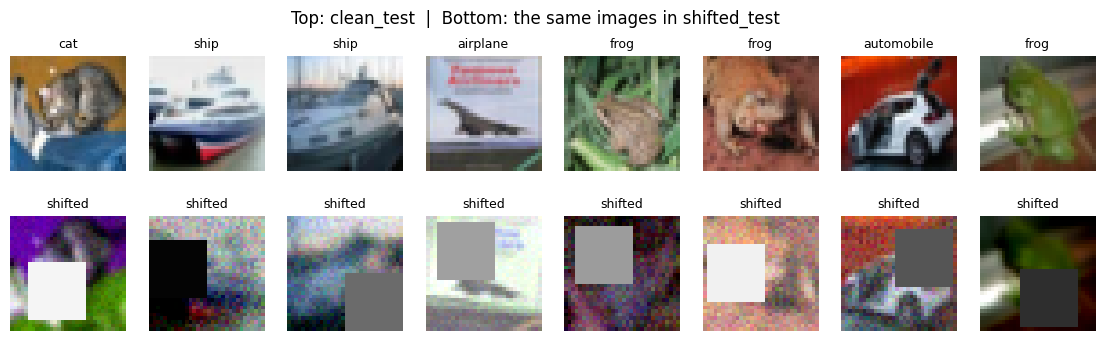

In [11]:
plt.figure(figsize=(14, 3.8))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_clean[i])
    plt.title(class_names[y_test[i]], fontsize=9)
    plt.axis('off')
    plt.subplot(2, 8, i + 9)
    plt.imshow(X_shifted[i])
    plt.title("shifted", fontsize=9)
    plt.axis('off')
plt.suptitle("Top: clean_test  |  Bottom: the same images in shifted_test")
plt.show()

### Model Architecture
Conv → BatchNorm → ReLU building block. BatchNorm momentum is 0.9 (instead of the default 0.99) because one epoch has only 13 updates, so the running statistics must adapt quickly for validation to be meaningful.

In [12]:
def conv_bn(x, filters, kernel_size):
    x = layers.Conv2D(filters, kernel_size, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    return layers.Activation('relu')(x)

Inception module: parallel 1×1, 3×3 and 5×5 branches with 1×1 reductions, plus a pooling branch, concatenated along channels.

In [13]:
def inception_module(x, f1, f3_red, f3, f5_red, f5, pool_proj):
    # Branch 1: 1x1 conv
    b1 = conv_bn(x, f1, 1)

    # Branch 2: 1x1 reduction -> 3x3 conv
    b2 = conv_bn(x, f3_red, 1)
    b2 = conv_bn(b2, f3, 3)

    # Branch 3: 1x1 reduction -> 5x5 conv
    b3 = conv_bn(x, f5_red, 1)
    b3 = conv_bn(b3, f5, 5)

    # Branch 4: 3x3 max pool -> 1x1 projection
    b4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    b4 = conv_bn(b4, pool_proj, 1)

    return layers.Concatenate()([b1, b2, b3, b4])

Full network: VGG-style 3×3 stem → Inception → pool → Inception → Global Average Pooling → Dense → Dropout → Softmax.

In [14]:
def build_model(width=1.0, dropout=0.0):
    def f(n):                     # scale the number of filters by 'width'
        return int(n * width)

    inputs = layers.Input(shape=(32, 32, 3))

    # Stem: small VGG-style 3x3 conv block
    x = conv_bn(inputs, f(32), 3)
    x = conv_bn(x, f(64), 3)
    x = layers.MaxPooling2D(2)(x)                                       # 32 -> 16

    # Two Inception modules
    x = inception_module(x, f(32), f(48), f(64), f(8), f(16), f(16))    # 16x16
    x = layers.MaxPooling2D(2)(x)                                       # 16 -> 8
    x = inception_module(x, f(64), f(64), f(96), f(16), f(32), f(32))   # 8x8

    # Head: Global Average Pooling instead of Flatten + large Dense layers
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(f(128), activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    return keras.Model(inputs, outputs)

Print the model summary and confirm the trainable-parameter count is under the 1,000,000 limit.

In [15]:
def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

model_check = build_model()
model_check.summary()

for w in [1.0, 1.5]:
    n_params = count_trainable(build_model(width=w))
    print(f"width={w}: trainable parameters = {n_params:,}  (limit 1,000,000 -> OK: {n_params <= 1_000_000})")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     18,432 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      3,072 │ max_pooling2d[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16, 8) │        512 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        192 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16, 8) │         32 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 16, 16, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ max_pooling2d[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │      2,048 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     27,648 │ activation_3[0][… │
│                     │ 64)               │            │                 

 Total params: 179,850 (702.54 KB)

 Trainable params: 178,682 (697.98 KB)

 Non-trainable params: 1,168 (4.56 KB)

width=1.0: trainable parameters = 178,682  (limit 1,000,000 -> OK: True)
width=1.5: trainable parameters = 399,442  (limit 1,000,000 -> OK: True)


### Augmentation and Training Pipeline
Geometric augmentation: horizontal flip, rotation (±30°), translation (±4 px, equivalent to random crop with 4-px padding) and zoom (±10%).

In [16]:
def build_geometric_aug():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(30 / 360, fill_mode='reflect'),          # up to ±30 degrees
        layers.RandomTranslation(0.125, 0.125, fill_mode='reflect'),   # up to 4 px (= crop with padding 4)
        layers.RandomZoom(0.1, fill_mode='reflect'),                   # scale ±10%
    ])

Photometric augmentation (part 1): per-image brightness/contrast and saturation jitter.

In [17]:
def random_brightness_contrast(images):
    n = tf.shape(images)[0]
    brightness = tf.random.uniform([n, 1, 1, 1], -0.25, 0.25)
    contrast = tf.random.uniform([n, 1, 1, 1], 0.6, 1.4)
    mean = tf.reduce_mean(images, axis=[1, 2, 3], keepdims=True)
    return (images - mean) * contrast + mean + brightness

def random_saturation(images):
    n = tf.shape(images)[0]
    saturation = tf.random.uniform([n, 1, 1, 1], 0.5, 1.5)
    gray = tf.reduce_mean(images, axis=3, keepdims=True)
    return gray + (images - gray) * saturation

Photometric augmentation (part 2): random Gaussian blur and Gaussian noise, then combine all photometric steps.

In [18]:
BLUR_KERNEL = tf.constant([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]]) / 16.0
BLUR_KERNEL = tf.tile(BLUR_KERNEL[:, :, None, None], [1, 1, 3, 1])     # 3x3 Gaussian, one per channel

def random_blur(images, p=0.3):
    n = tf.shape(images)[0]
    blurred = tf.nn.depthwise_conv2d(images, BLUR_KERNEL, strides=[1, 1, 1, 1], padding='SAME')
    apply = tf.cast(tf.random.uniform([n, 1, 1, 1]) < p, tf.float32)
    return apply * blurred + (1 - apply) * images

def random_noise(images, p=0.3):
    n = tf.shape(images)[0]
    std = tf.random.uniform([n, 1, 1, 1], 0.0, 0.06)
    apply = tf.cast(tf.random.uniform([n, 1, 1, 1]) < p, tf.float32)
    return images + apply * std * tf.random.normal(tf.shape(images))

def photometric_aug(images):
    images = random_brightness_contrast(images)
    images = random_saturation(images)
    images = random_blur(images)
    images = random_noise(images)
    return tf.clip_by_value(images, 0.0, 1.0)

Random Erasing (Cutout): erase a random 8–16 px square with a random colour, with probability 0.5.

In [19]:
def random_erasing(images, p=0.5):
    n = tf.shape(images)[0]
    half = tf.random.uniform([n, 1, 1], 4, 9, dtype=tf.int32)        # patch side 8..16 px
    cy = tf.random.uniform([n, 1, 1], 0, 32, dtype=tf.int32)
    cx = tf.random.uniform([n, 1, 1], 0, 32, dtype=tf.int32)
    rows = tf.range(32)[None, :, None]
    cols = tf.range(32)[None, None, :]

    inside = (tf.abs(rows - cy) < half) & (tf.abs(cols - cx) < half)   # (n, 32, 32)
    apply = tf.random.uniform([n, 1, 1]) < p
    mask = tf.cast(inside & apply, tf.float32)[..., None]

    fill = tf.random.uniform([n, 1, 1, 3])                               # random colour patch
    return mask * fill + (1 - mask) * images

Mixup: blend each image (and its one-hot label) with another random image from the batch, λ ~ Beta(0.2, 0.2).

In [20]:
def sample_beta(n, alpha):
    a = tf.random.gamma([n], alpha)
    b = tf.random.gamma([n], alpha)
    return a / (a + b)

def mixup(images, labels, alpha=0.2):
    n = tf.shape(images)[0]
    lam = sample_beta(n, alpha)
    index = tf.random.shuffle(tf.range(n))

    lam_img = tf.reshape(lam, [n, 1, 1, 1])
    lam_lbl = tf.reshape(lam, [n, 1])
    images = lam_img * images + (1 - lam_img) * tf.gather(images, index)
    labels = lam_lbl * labels + (1 - lam_lbl) * tf.gather(labels, index)
    return images, labels

Training dataset: shuffle → batch → augment on the fly. Each augmentation is switched on/off by the config. Validation and test data are never augmented.

In [21]:
def make_train_ds(config, seed):
    geometric_aug = build_geometric_aug()     # built after set_seed -> reproducible

    def augment(images, labels):
        if config['geometric']:
            images = geometric_aug(images, training=True)
        if config['photometric']:
            images = photometric_aug(images)
        if config['erasing']:
            images = random_erasing(images)
        if config['mixup']:
            images, labels = mixup(images, labels)
        return images, labels

    ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr_oh))
    ds = ds.shuffle(len(X_tr), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(augment)                       # applied on the fly, training data only
    return ds.prefetch(tf.data.AUTOTUNE)

Base configuration: everything off. Later parts switch individual options on.

In [22]:
BASE_CONFIG = dict(
    geometric=False, photometric=False, erasing=False, mixup=False,
    width=1.0, dropout=0.0, weight_decay=0.0, label_smoothing=0.0,
    lr=1e-3, cosine_lr=False, early_stopping=False,
)
BASE_CONFIG

{'geometric': False,
 'photometric': False,
 'erasing': False,
 'mixup': False,
 'width': 1.0,
 'dropout': 0.0,
 'weight_decay': 0.0,
 'label_smoothing': 0.0,
 'lr': 0.001,
 'cosine_lr': False,
 'early_stopping': False}

Train one model with a given config and seed.

In [23]:
def train_one(config, seed):
    set_seed(seed)
    model = build_model(width=config['width'], dropout=config['dropout'])

    steps_per_epoch = int(np.ceil(len(X_tr) / BATCH_SIZE))
    if config['cosine_lr']:
        lr = keras.optimizers.schedules.CosineDecay(config['lr'], decay_steps=EPOCHS * steps_per_epoch)
    else:
        lr = config['lr']

    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=config['weight_decay']),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=config['label_smoothing']),
                  metrics=['accuracy'])

    callbacks = []
    if config['early_stopping']:
        callbacks.append(keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=15,
                                                       start_from_epoch=10, restore_best_weights=True))

    history = model.fit(make_train_ds(config, seed),
                        validation_data=(X_val, y_val_oh),
                        epochs=EPOCHS, callbacks=callbacks, verbose=0)
    return model, history.history

Robust validation set: the 100 validation images passed 5 times through our own training augmentations (geometric + photometric + Random Erasing) with a fixed seed. It contains **no test image and no hidden corruption**. Clean validation accuracy cannot tell which model is more robust, so model selection uses this set.

In [24]:
def make_robust_val(copies=5):
    set_seed(DATA_SEED)
    geo = build_geometric_aug()
    images = tf.constant(np.repeat(X_val, copies, axis=0))
    images = geo(images, training=True)
    images = photometric_aug(images)
    images = random_erasing(images)
    return images.numpy(), np.repeat(y_val, copies)

X_val_rob, y_val_rob = make_robust_val()
print("Robust validation set:", X_val_rob.shape)

Robust validation set: (500, 32, 32, 3)


Accuracy helpers: train (clean, un-augmented), validation, clean test and shifted test.

In [25]:
def accuracy(model, X, y):
    probs = model.predict(X, batch_size=500, verbose=0)
    return np.mean(np.argmax(probs, axis=1) == y)

def evaluate(model):
    return {'train': accuracy(model, X_tr, y_tr),
            'val': accuracy(model, X_val, y_val),
            'val_rob': accuracy(model, X_val_rob, y_val_rob),
            'clean': accuracy(model, X_clean, y_test),
            'shifted': accuracy(model, X_shifted, y_test)}

Run one configuration with all 3 seeds and collect scores, learning curves and models. Only train / validation numbers are printed during training. All selections use the robust validation accuracy; test accuracies are only shown in the result tables.

In [26]:
def run_experiment(name, config):
    scores, histories, models = [], [], []
    for seed in SEEDS:
        start = time.time()
        model, history = train_one(config, seed)
        s = evaluate(model)
        # Only train/val are printed here: every decision is made on validation accuracy
        print(f"{name} | seed {seed} | epochs run: {len(history['loss'])} | "
              f"train {s['train']:.3f} | val {s['val']:.3f} | robust val {s['val_rob']:.3f} | {time.time() - start:.0f}s")
        scores.append(s)
        histories.append(history)
        models.append(model)
    return {'config': config, 'scores': pd.DataFrame(scores), 'histories': histories, 'models': models}

def mean_std(scores, col):
    return f"{scores[col].mean() * 100:.2f} ± {scores[col].std() * 100:.2f}"

Plot helper for learning curves (loss and accuracy for each seed).

In [27]:
def plot_curves(histories, title):
    plt.figure(figsize=(13, 4))

    plt.subplot(1, 2, 1)
    for seed, h in zip(SEEDS, histories):
        plt.plot(h['loss'], label=f'Train loss (seed {seed})')
        plt.plot(h['val_loss'], '--', label=f'Val loss (seed {seed})')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title(title + " - Loss")
    plt.legend(fontsize=7)

    plt.subplot(1, 2, 2)
    for seed, h in zip(SEEDS, histories):
        plt.plot(h['accuracy'], label=f'Train acc (seed {seed})')
        plt.plot(h['val_accuracy'], '--', label=f'Val acc (seed {seed})')
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title(title + " - Accuracy")
    plt.legend(fontsize=7)
    plt.show()

### Part A: Baseline
Train the network on the 400 training images with **no augmentation** and no extra regularization (BatchNorm is part of the architecture), 60 epochs, constant learning rate.

In [28]:
baseline = run_experiment("Baseline", BASE_CONFIG)

Baseline | seed 42 | epochs run: 60 | train 1.000 | val 0.470 | robust val 0.238 | 41s
Baseline | seed 123 | epochs run: 60 | train 1.000 | val 0.430 | robust val 0.268 | 36s
Baseline | seed 2026 | epochs run: 60 | train 1.000 | val 0.530 | robust val 0.260 | 36s


Report training, validation, clean-test and shifted-test accuracy (mean ± std over 3 seeds).

In [29]:
baseline_table = pd.DataFrame({
    'Train': [mean_std(baseline['scores'], 'train')],
    'Val': [mean_std(baseline['scores'], 'val')],
    'Clean Test': [mean_std(baseline['scores'], 'clean')],
    'Shifted Test': [mean_std(baseline['scores'], 'shifted')],
}, index=['Baseline (no augmentation)'])

print("Accuracy in %, mean ± std over seeds", SEEDS)
baseline_table

Accuracy in %, mean ± std over seeds [42, 123, 2026]


,Train,Val,Clean Test,Shifted Test
Baseline (no augmentation),100.00 ± 0.00,47.67 ± 5.03,43.01 ± 2.77,18.83 ± 0.44


Plot the baseline learning curves.

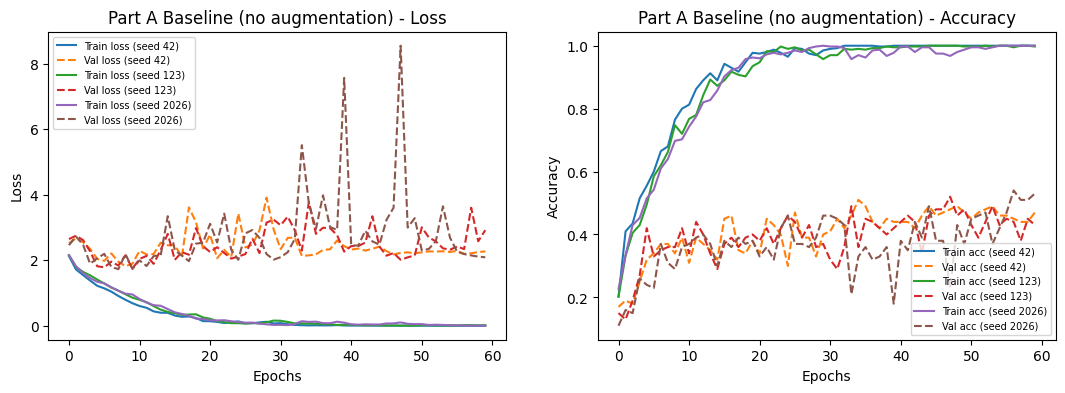

In [30]:
plot_curves(baseline['histories'], "Part A Baseline (no augmentation)")

Measure the two gaps used in the diagnosis.

In [31]:
b = baseline['scores'].mean() * 100
print(f"Train - Val gap        : {b['train'] - b['val']:.2f} points  (overfitting)")
print(f"Clean - Shifted gap    : {b['clean'] - b['shifted']:.2f} points  (covariate shift)")

Train - Val gap        : 52.33 points  (overfitting)
Clean - Shifted gap    : 24.18 points  (covariate shift)


## Part A Conclusion
- **Results (mean ± std, 3 seeds):** train 100.00 ± 0.00%, validation 47.67 ± 5.03%, clean test 43.01 ± 2.77%, shifted test 18.83 ± 0.44%.
- **Overfitting:** training accuracy reaches 100% and training loss goes to ~0, while validation accuracy stays near 45% and validation loss rises and spikes (up to 8). The 52.33-point train–validation gap shows the network **memorizes** the 400 images.
- **Covariate shift:** accuracy falls a further 24.18 points from clean test to shifted test. Rotation, brightness/contrast change, blur, noise, occlusion and channel swap move the test images away from the clean training distribution, so features learned on clean images do not transfer.
- **Diagnosis: both.** Overfitting explains the train → clean-test gap and covariate shift explains the extra clean → shifted gap, so both regularization and augmentation are needed.

### Part B: Augmentation Strategy
Visualize each augmentation family on one training image.

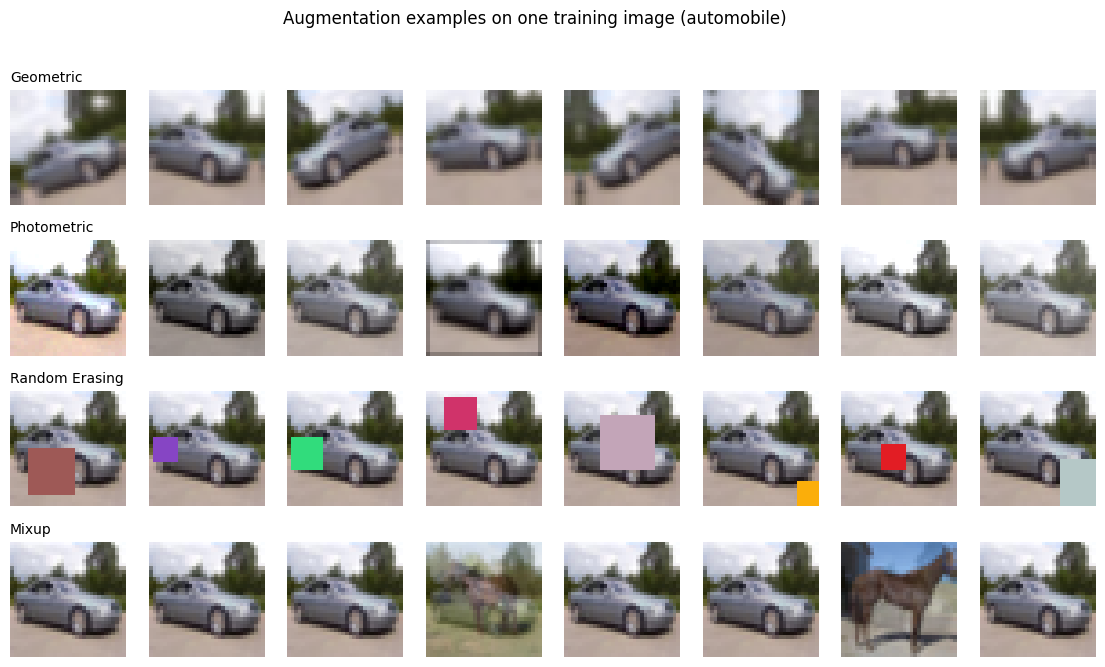

In [32]:
set_seed(DATA_SEED)
sample = tf.constant(np.repeat(X_tr[:1], 8, axis=0))      # the same image copied 8 times
sample_lbl = tf.constant(np.repeat(y_tr_oh[:1], 8, axis=0))
other = tf.constant(X_tr[1:9])                             # 8 different images for the Mixup demo
other_lbl = tf.constant(y_tr_oh[1:9])

geo_demo = build_geometric_aug()
mix_imgs, _ = mixup(tf.concat([sample, other], 0), tf.concat([sample_lbl, other_lbl], 0))

rows = {
    'Geometric': geo_demo(sample, training=True),
    'Photometric': photometric_aug(sample),
    'Random Erasing': random_erasing(sample, p=1.0),
    'Mixup': mix_imgs[:8],
}

plt.figure(figsize=(14, 7.5))
for r, (name, imgs) in enumerate(rows.items()):
    for i in range(8):
        plt.subplot(4, 8, r * 8 + i + 1)
        plt.imshow(np.clip(imgs[i].numpy(), 0, 1))
        plt.axis('off')
        if i == 0:
            plt.title(name, fontsize=10, loc='left')
plt.suptitle(f"Augmentation examples on one training image ({class_names[y_tr[0]]})")
plt.show()

### Chosen augmentations and justification

| Augmentation | Setting | Targets in shifted test |
|---|---|---|
| Horizontal flip | p = 0.5 | viewpoint variation (all CIFAR classes are left/right symmetric) |
| Rotation | ±30° | rotation up to ±25° |
| Translation / crop | ±4 px (≈ pad-4 random crop) | small position shifts |
| Zoom | ±10% | scale changes |
| Brightness / contrast | ±0.25 / ×0.6–1.4 | darkened / brightened images |
| Saturation | ×0.5–1.5 | colour changes; reduces reliance on exact colour |
| Gaussian blur | 3×3, p = 0.3 | blur |
| Gaussian noise | σ ≤ 0.06, p = 0.3 | noise |
| Random Erasing | 8–16 px square, random colour, p = 0.5 | ~25% occlusion |
| Mixup + label smoothing | α = 0.2, ε = 0.1 | over-confidence on unfamiliar inputs |

Channel swap / grayscale are deliberately **not** used, so the hidden corruption stays unseen during training.

**Would vertical flip help or hurt?** It would **hurt**. CIFAR-10 objects have a natural upright orientation: sky above airplanes and ships, wheels below cars and trucks, animals standing on the ground. Vertically flipped images never occur in the test set (it only has ±25° rotation), so vertical flips teach the model unrealistic inputs and use up its limited capacity.

**Rotation ±90° in training but only ±25° in test, what is the trade-off?** A wider range makes the model more rotation-invariant, but most training samples then sit at angles that never occur at test time, and the black/reflected corners grow. The small model spends capacity on impossible poses and fits the realistic ±25° range less well, so clean and shifted accuracy usually drop. A range slightly larger than the test range (±30°) covers the shift without wasting capacity.

**Why can too much augmentation reduce accuracy on a small model?** Augmentation makes the training distribution wider and harder. A model with < 1M parameters and only 400 images has limited capacity; if transforms are too strong (huge rotations, heavy erasing, strong colour changes) or all applied together at full strength, the network **underfits**: training accuracy falls, the class signal is partly destroyed, and the model cannot fit both the clean and augmented variants. Augmentation must match the expected shift, not be maximal.

### Part C: Regularization and Training Design
Techniques used (and where they are placed):
- **BatchNorm** after every convolution (Conv → BN → ReLU): stabilizes training on tiny batches of heavily augmented data and adds mild noise-based regularization. It is used inside the conv blocks, where activation statistics shift the most.
- **Dropout** only after the Dense(128) layer, not between early convolutions: conv feature maps are spatially correlated, so dropping single activations barely removes information (neighbours carry the same signal), and it interferes with BatchNorm statistics. The fully connected head is where co-adapted, memorizing units appear, so Dropout there is most effective.
- **Weight decay (AdamW, decoupled)**: keeps weights small to limit memorization. Decoupled decay is used because L2 inside Adam is rescaled by the adaptive learning rate and loses its effect.
- **Cosine learning-rate decay**: large steps early, small steps late for a stable final solution; it does not depend on the noisy 100-image validation signal.
- **Early stopping** on validation accuracy (patience 15, ignoring the first 10 epochs, restore best weights). Validation *loss* is not used: on 400 images it is lowest in the first few epochs and then rises while accuracy is still improving, so monitoring it restores almost untrained weights.
- **Label smoothing (0.1)**: used together with Mixup in Part D; prevents over-confident predictions.

Small search over dropout and weight decay using validation images only (geometric + photometric augmentation, 3 seeds each).

In [33]:
reg_grid = [(0.3, 0.005), (0.3, 0.05), (0.5, 0.005), (0.5, 0.05)]   # (dropout, weight decay)

reg_results = {}
for dropout, wd in reg_grid:
    config = {**BASE_CONFIG, 'geometric': True, 'photometric': True,
              'dropout': dropout, 'weight_decay': wd,
              'cosine_lr': True, 'early_stopping': True}
    reg_results[(dropout, wd)] = run_experiment(f"dropout={dropout}, wd={wd}", config)

dropout=0.3, wd=0.005 | seed 42 | epochs run: 47 | train 0.623 | val 0.460 | robust val 0.292 | 52s
dropout=0.3, wd=0.005 | seed 123 | epochs run: 38 | train 0.490 | val 0.420 | robust val 0.312 | 45s
dropout=0.3, wd=0.005 | seed 2026 | epochs run: 57 | train 0.608 | val 0.520 | robust val 0.352 | 62s
dropout=0.3, wd=0.05 | seed 42 | epochs run: 55 | train 0.625 | val 0.460 | robust val 0.352 | 61s
dropout=0.3, wd=0.05 | seed 123 | epochs run: 34 | train 0.460 | val 0.420 | robust val 0.328 | 41s
dropout=0.3, wd=0.05 | seed 2026 | epochs run: 60 | train 0.608 | val 0.450 | robust val 0.324 | 64s
dropout=0.5, wd=0.005 | seed 42 | epochs run: 47 | train 0.537 | val 0.450 | robust val 0.324 | 54s
dropout=0.5, wd=0.005 | seed 123 | epochs run: 33 | train 0.425 | val 0.430 | robust val 0.308 | 43s
dropout=0.5, wd=0.005 | seed 2026 | epochs run: 46 | train 0.480 | val 0.420 | robust val 0.310 | 52s
dropout=0.5, wd=0.05 | seed 42 | epochs run: 47 | train 0.482 | val 0.440 | robust val 0.304 |

Select the best dropout / weight-decay pair using the mean robust validation accuracy only.

In [34]:
reg_table = pd.DataFrame({
    'Dropout': [k[0] for k in reg_results],
    'Weight decay': [k[1] for k in reg_results],
    'Val Acc (mean ± std)': [mean_std(reg_results[k]['scores'], 'val') for k in reg_results],
    'Robust Val Acc (mean ± std)': [mean_std(reg_results[k]['scores'], 'val_rob') for k in reg_results],
})

# Choose using validation images only (robust validation accuracy)
best_key = max(reg_results, key=lambda k: reg_results[k]['scores']['val_rob'].mean())
REG = dict(dropout=best_key[0], weight_decay=best_key[1], cosine_lr=True, early_stopping=True)

print("Selected regularization (by robust val accuracy):", REG)
reg_table

Selected regularization (by robust val accuracy): {'dropout': 0.3, 'weight_decay': 0.05, 'cosine_lr': True, 'early_stopping': True}


,Dropout,Weight decay,Val Acc (mean ± std),Robust Val Acc (mean ± std)
0,0.3,0.005,46.67 ± 5.03,31.87 ± 3.06
1,0.3,0.050,44.33 ± 2.08,33.47 ± 1.51
2,0.5,0.005,43.33 ± 1.53,31.40 ± 0.87
3,0.5,0.050,43.67 ± 1.53,27.80 ± 2.25


Learning curves of the selected regularized model (compare with the baseline curves in Part A).

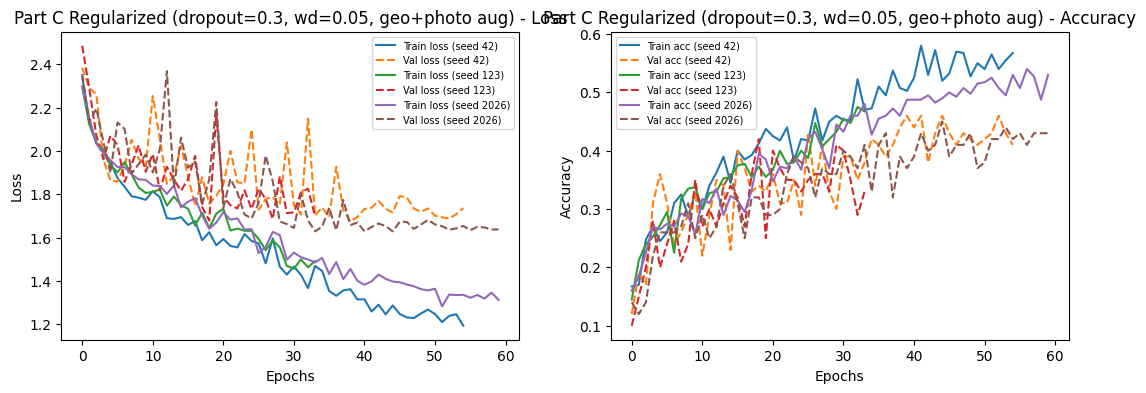

In [35]:
plot_curves(reg_results[best_key]['histories'],
            f"Part C Regularized (dropout={REG['dropout']}, wd={REG['weight_decay']}, geo+photo aug)")

Learning-rate schedule used (cosine decay vs. constant baseline).

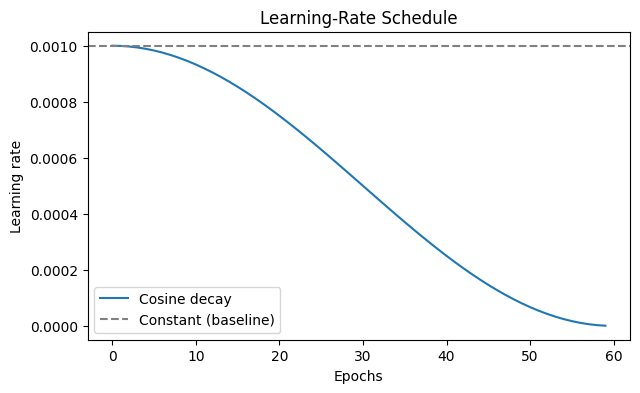

In [36]:
steps_per_epoch = int(np.ceil(len(X_tr) / BATCH_SIZE))
schedule = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=EPOCHS * steps_per_epoch)
lrs = [float(schedule(e * steps_per_epoch)) for e in range(EPOCHS)]

plt.figure(figsize=(7, 4))
plt.plot(lrs, label='Cosine decay')
plt.axhline(1e-3, color='gray', linestyle='--', label='Constant (baseline)')
plt.xlabel("Epochs")
plt.ylabel("Learning rate")
plt.title("Learning-Rate Schedule")
plt.legend()
plt.show()

## Part C Conclusion
- **Selected:** dropout 0.3, weight decay 0.05 (robust validation 33.47 ± 1.51%). The four settings are close (27.80 – 33.47%) and three of them lie within one standard deviation of each other, so this choice is a weak preference, not a clear winner. Only dropout 0.5 with weight decay 0.05 is clearly worse (27.80%): too much regularization for this small model.
- **Effect on overfitting:** in the baseline the training accuracy reaches 100% and the validation loss climbs to 2–8. With regularization and geometric + photometric augmentation the training accuracy stays at 46–63%, the validation accuracy ends at 42–46%, and the validation loss falls steadily to about 1.65–1.75 instead of rising. The train–validation gap shrinks from 52 points to roughly 10–15 points.
- **Cost:** the model no longer fits its own training set (train accuracy well below 100% after 60 epochs), so it is now limited by underfitting rather than memorization.
- `REG` is reused in every configuration of Part D, so the ablation isolates the effect of augmentation.

### Part D: Ablation Study
Define the ablation configurations. All use the regularization selected in Part C (`REG`); only the augmentation changes.

In [37]:
ABL = {**BASE_CONFIG, **REG}

ablation_configs = {
    'No augmentation': {**ABL},
    'Geometric only (crop, flip, rotation)': {**ABL, 'geometric': True},
    'Photometric only (color jitter, blur, noise)': {**ABL, 'photometric': True},
    'Geometric + photometric': {**ABL, 'geometric': True, 'photometric': True},
    '+ Cutout / Random Erasing': {**ABL, 'geometric': True, 'photometric': True, 'erasing': True},
    '+ Mixup + label smoothing': {**ABL, 'geometric': True, 'photometric': True, 'erasing': True,
                                  'mixup': True, 'label_smoothing': 0.1},
}

Train every configuration with 3 seeds. "Geometric + photometric" is identical to the selected Part C run (same config, same seeds), so it is reused instead of retrained.

In [38]:
ablation = {}
for name, config in ablation_configs.items():
    if name == 'Geometric + photometric':
        ablation[name] = reg_results[best_key]     # identical config + seeds already trained in Part C
        print(name, "-> reused from Part C")
    else:
        ablation[name] = run_experiment(name, config)

No augmentation | seed 42 | epochs run: 41 | train 0.983 | val 0.490 | robust val 0.238 | 30s
No augmentation | seed 123 | epochs run: 60 | train 1.000 | val 0.550 | robust val 0.268 | 43s
No augmentation | seed 2026 | epochs run: 59 | train 1.000 | val 0.550 | robust val 0.280 | 38s
Geometric only (crop, flip, rotation) | seed 42 | epochs run: 60 | train 0.805 | val 0.420 | robust val 0.280 | 55s
Geometric only (crop, flip, rotation) | seed 123 | epochs run: 37 | train 0.603 | val 0.390 | robust val 0.260 | 39s
Geometric only (crop, flip, rotation) | seed 2026 | epochs run: 60 | train 0.748 | val 0.400 | robust val 0.284 | 53s
Photometric only (color jitter, blur, noise) | seed 42 | epochs run: 38 | train 0.780 | val 0.480 | robust val 0.328 | 33s
Photometric only (color jitter, blur, noise) | seed 123 | epochs run: 59 | train 0.927 | val 0.590 | robust val 0.372 | 53s
Photometric only (color jitter, blur, noise) | seed 2026 | epochs run: 60 | train 0.948 | val 0.530 | robust val 0.37

Final-model selection: every ablation configuration plus the full augmentation stack on a 1.5× wider network (still < 1M parameters) is a candidate. The one with the highest mean robust validation accuracy is selected.

In [39]:
# Extra candidate: the full augmentation stack on a 1.5x wider network (still < 1M parameters)
wide_config = {**ablation_configs['+ Mixup + label smoothing'], 'width': 1.5}
wide = run_experiment("Full stack, width 1.5", wide_config)

candidates = {**ablation, 'Full stack, width 1.5': wide}
for name, res in candidates.items():
    print(f"{name}: val = {mean_std(res['scores'], 'val')} | robust val = {mean_std(res['scores'], 'val_rob')}")

# Choose using validation images only (robust validation accuracy)
final_name = max(candidates, key=lambda k: candidates[k]['scores']['val_rob'].mean())
final = candidates[final_name]
print()
print("Selected final model:", final_name)

Full stack, width 1.5 | seed 42 | epochs run: 60 | train 0.522 | val 0.480 | robust val 0.388 | 67s
Full stack, width 1.5 | seed 123 | epochs run: 60 | train 0.573 | val 0.440 | robust val 0.354 | 68s
Full stack, width 1.5 | seed 2026 | epochs run: 26 | train 0.415 | val 0.370 | robust val 0.266 | 37s
No augmentation: val = 53.00 ± 3.46 | robust val = 26.20 ± 2.16
Geometric only (crop, flip, rotation): val = 40.33 ± 1.53 | robust val = 27.47 ± 1.29
Photometric only (color jitter, blur, noise): val = 53.33 ± 5.51 | robust val = 35.93 ± 2.73
Geometric + photometric: val = 44.33 ± 2.08 | robust val = 33.47 ± 1.51
+ Cutout / Random Erasing: val = 45.33 ± 0.58 | robust val = 35.87 ± 3.30
+ Mixup + label smoothing: val = 47.67 ± 2.08 | robust val = 36.00 ± 3.62
Full stack, width 1.5: val = 43.00 ± 5.57 | robust val = 33.60 ± 6.30

Selected final model: + Mixup + label smoothing


Ablation table: validation, clean-test and shifted-test accuracy (%, mean ± std over 3 seeds).

In [40]:
all_rows = {**ablation, f'Final model ({final_name})': final}

ablation_table = pd.DataFrame({
    'Val Acc': [mean_std(r['scores'], 'val') for r in all_rows.values()],
    'Robust Val': [mean_std(r['scores'], 'val_rob') for r in all_rows.values()],
    'Clean Test': [mean_std(r['scores'], 'clean') for r in all_rows.values()],
    'Shifted Test': [mean_std(r['scores'], 'shifted') for r in all_rows.values()],
}, index=all_rows.keys())

print("Accuracy in %, mean ± std over seeds", SEEDS)
ablation_table

Accuracy in %, mean ± std over seeds [42, 123, 2026]


,Val Acc,Robust Val,Clean Test,Shifted Test
No augmentation,53.00 ± 3.46,26.20 ± 2.16,41.71 ± 3.06,18.38 ± 1.21
"Geometric only (crop, flip, rotation)",40.33 ± 1.53,27.47 ± 1.29,38.08 ± 1.73,19.15 ± 0.70
"Photometric only (color jitter, blur, noise)",53.33 ± 5.51,35.93 ± 2.73,43.56 ± 2.22,21.33 ± 0.91
Geometric + photometric,44.33 ± 2.08,33.47 ± 1.51,38.85 ± 3.09,22.71 ± 0.92
+ Cutout / Random Erasing,45.33 ± 0.58,35.87 ± 3.30,39.49 ± 3.67,23.34 ± 1.76
+ Mixup + label smoothing,47.67 ± 2.08,36.00 ± 3.62,38.06 ± 3.68,23.20 ± 2.97
Final model (+ Mixup + label smoothing),47.67 ± 2.08,36.00 ± 3.62,38.06 ± 3.68,23.20 ± 2.97


Plot clean vs. shifted test accuracy for every configuration.

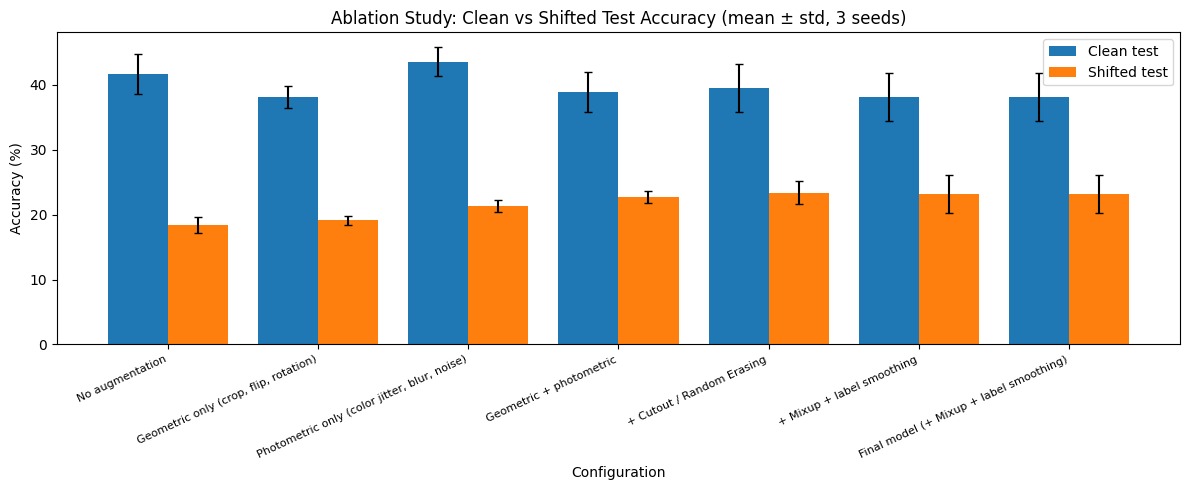

In [41]:
names = list(all_rows.keys())
shift_mean = [all_rows[n]['scores']['shifted'].mean() * 100 for n in names]
shift_std = [all_rows[n]['scores']['shifted'].std() * 100 for n in names]
clean_mean = [all_rows[n]['scores']['clean'].mean() * 100 for n in names]
clean_std = [all_rows[n]['scores']['clean'].std() * 100 for n in names]

x = np.arange(len(names))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, clean_mean, 0.4, yerr=clean_std, capsize=3, label='Clean test')
plt.bar(x + 0.2, shift_mean, 0.4, yerr=shift_std, capsize=3, label='Shifted test')
plt.xticks(x, names, rotation=25, ha='right', fontsize=8)
plt.xlabel("Configuration")
plt.ylabel("Accuracy (%)")
plt.title("Ablation Study: Clean vs Shifted Test Accuracy (mean ± std, 3 seeds)")
plt.legend()
plt.tight_layout()
plt.show()

Measure the shifted-test gain of each augmentation family and of each step of the stack.

In [42]:
no_aug = ablation['No augmentation']['scores']['shifted'].mean() * 100

print("Shifted-test gain of each single augmentation family over 'No augmentation':")
for name in ['Geometric only (crop, flip, rotation)', 'Photometric only (color jitter, blur, noise)']:
    print(f"  {name}: {ablation[name]['scores']['shifted'].mean() * 100 - no_aug:+.2f}")

print("\nShifted-test gain of each step in the cumulative stack:")
steps = list(ablation.keys())[3:]
prev = no_aug
for name in steps:
    cur = ablation[name]['scores']['shifted'].mean() * 100
    print(f"  {name}: {cur - prev:+.2f}")
    prev = cur

Shifted-test gain of each single augmentation family over 'No augmentation':
  Geometric only (crop, flip, rotation): +0.77
  Photometric only (color jitter, blur, noise): +2.95

Shifted-test gain of each step in the cumulative stack:
  Geometric + photometric: +4.32
  + Cutout / Random Erasing: +0.64
  + Mixup + label smoothing: -0.15


## Part D Conclusion
- **Largest gain: photometric augmentation.** On its own it raises shifted-test accuracy by +2.95 points (18.38 → 21.33%), against +0.77 for geometric alone. It matches the **brightness / contrast change**, which is applied to every shifted-test image, and the **blur and noise**, each applied to half of them. A model trained only on clean, sharp, normally exposed images has never seen these pixel statistics.
- **Geometric augmentation** (matches the ±25° rotation) gives little alone (+0.77) and lowers clean-test accuracy (41.71 → 38.08%): with only 60 epochs the model cannot fit the rotated/shifted images (train accuracy 60–80%). Combined with photometric it is worth more: geometric + photometric is +4.32 over no augmentation, more than the two single gains added together (3.72).
- **Random Erasing** (matches the 25% occlusion) adds +0.64 and **Mixup + label smoothing** changes the mean by −0.15. Both are smaller than the seed-to-seed spread (std 1.76 and 2.97), so this run does not show a real benefit from either.
- **Final model:** "+ Mixup + label smoothing" has the highest robust validation accuracy (36.00%), but "Photometric only" (35.93%) and "+ Random Erasing" (35.87%) are effectively tied with it. Its shifted-test accuracy is 23.20 ± 2.97%; the large std comes from seed 2026, which stopped at epoch 39 and reached only 19.77%.
- **Trade-off against the baseline:** shifted-test accuracy improves by 4.37 points (18.83 → 23.20%), but clean-test accuracy falls by 4.95 points (43.01 → 38.06%). The final model's training accuracy is only 45–56%, so the full augmentation stack makes this small model underfit, which is the effect described in Part B.

### Part E: Error Analysis
Predictions of the final model (seed 42) on the clean and shifted test sets.

In [43]:
final_model = final['models'][0]          # seed 42 model of the final configuration
print("Error analysis uses the final model trained with seed", SEEDS[0])

probs_shifted = final_model.predict(X_shifted, batch_size=500, verbose=0)
pred_shifted = np.argmax(probs_shifted, axis=1)
pred_clean = np.argmax(final_model.predict(X_clean, batch_size=500, verbose=0), axis=1)

Error analysis uses the final model trained with seed 42


Per-class accuracy on clean and shifted test.

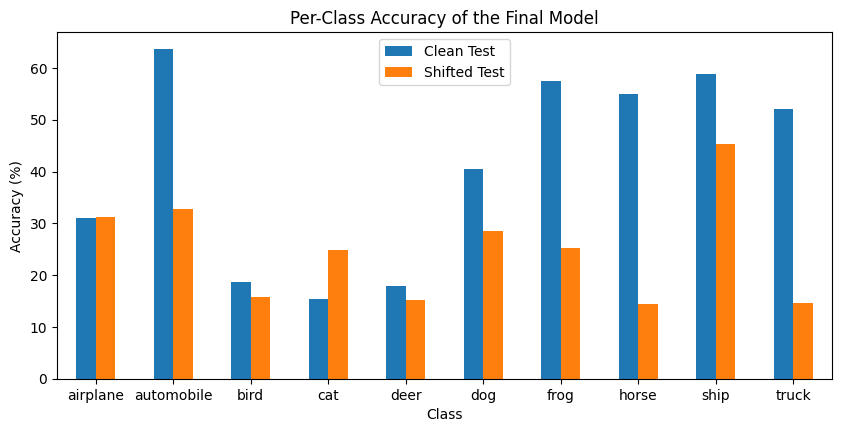

,Clean Test,Shifted Test
airplane,31.0,31.3
automobile,63.7,32.7
bird,18.7,15.7
cat,15.4,24.8
deer,17.9,15.2
dog,40.4,28.6
frog,57.5,25.3
horse,55.0,14.4
ship,58.8,45.4
truck,52.0,14.6


In [44]:
per_class = pd.DataFrame({
    'Clean Test': [np.mean(pred_clean[y_test == c] == c) * 100 for c in range(10)],
    'Shifted Test': [np.mean(pred_shifted[y_test == c] == c) * 100 for c in range(10)],
}, index=class_names).round(2)

per_class.plot(kind='bar', figsize=(10, 4.5))
plt.xlabel("Class")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy of the Final Model")
plt.xticks(rotation=0)
plt.legend()
plt.show()

per_class

Normalized confusion matrix on the shifted test set (each row sums to 1).

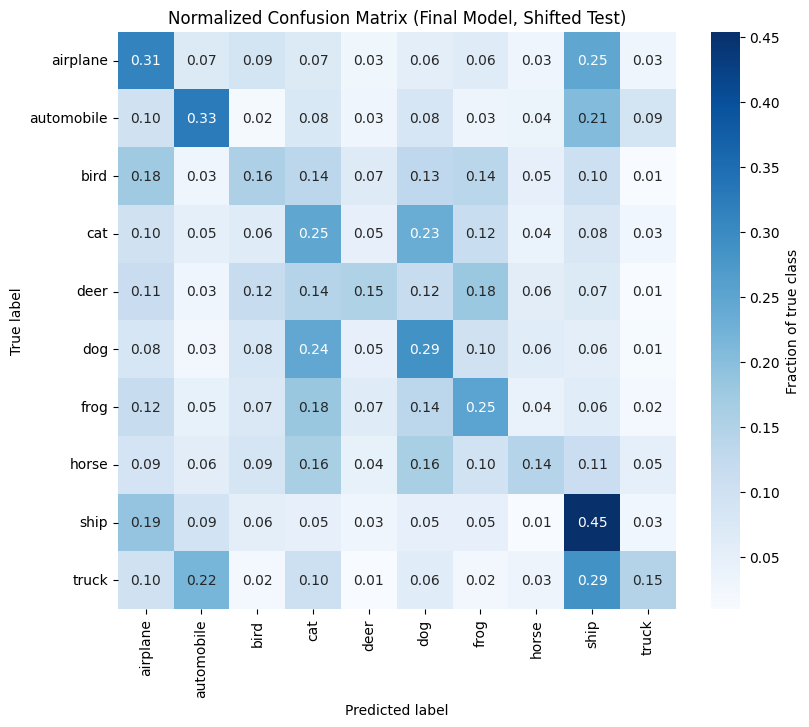

In [45]:
cm = confusion_matrix(y_test, pred_shifted, normalize='true')

plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Fraction of true class'})
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Normalized Confusion Matrix (Final Model, Shifted Test)")
plt.show()

Most confused class pairs (off-diagonal entries of the normalized confusion matrix).

In [46]:
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((class_names[i], class_names[j], cm[i, j] * 100))

pairs = pd.DataFrame(pairs, columns=['True', 'Predicted as', '% of true class'])
pairs.sort_values('% of true class', ascending=False).head(6).round(2)

,True,Predicted as,% of true class
89,truck,ship,28.6
7,airplane,ship,24.9
48,dog,cat,24.5
31,cat,dog,23.5
82,truck,automobile,21.9
16,automobile,ship,20.6


The 8 most confident misclassifications on the shifted test set (top: clean original, bottom: shifted input with prediction and confidence).

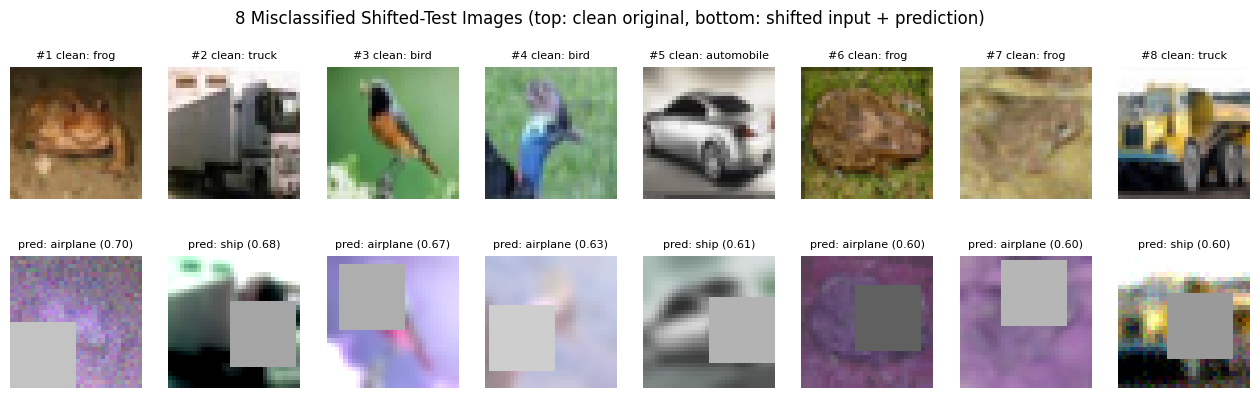

In [47]:
# wrong on the shifted image but correct on its clean original -> the corruption caused the failure
wrong = np.where((pred_shifted != y_test) & (pred_clean == y_test))[0]
confidence = probs_shifted[wrong, pred_shifted[wrong]]
chosen = wrong[np.argsort(-confidence)[:8]]       # the 8 most confident mistakes

plt.figure(figsize=(16, 4.5))
for k, i in enumerate(chosen):
    plt.subplot(2, 8, k + 1)
    plt.imshow(X_clean[i])
    plt.title(f"#{k + 1} clean: {class_names[y_test[i]]}", fontsize=8)
    plt.axis('off')
    plt.subplot(2, 8, k + 9)
    plt.imshow(X_shifted[i])
    plt.title(f"pred: {class_names[pred_shifted[i]]} ({probs_shifted[i].max():.2f})", fontsize=8)
    plt.axis('off')
plt.suptitle("8 Misclassified Shifted-Test Images (top: clean original, bottom: shifted input + prediction)")
plt.show()

Corruption parameters that were applied to each of these 8 images (recorded when `shifted_test` was built).

In [48]:
mis_table = shift_info.loc[chosen, ['angle', 'brightness', 'contrast', 'blur', 'noise',
                                     'occ_y', 'occ_x', 'swapped']].copy()
mis_table.insert(0, 'True', [class_names[y_test[i]] for i in chosen])
mis_table.insert(1, 'Predicted', [class_names[pred_shifted[i]] for i in chosen])
mis_table.index = [f"#{k + 1}" for k in range(8)]
mis_table.round(2)

,True,Predicted,angle,brightness,contrast,blur,noise,occ_y,occ_x,swapped
#1,frog,airplane,-14.77,0.27,0.62,0.66,0.05,16,0,True
#2,truck,ship,-5.50,-0.05,1.40,0.79,0.00,11,15,True
#3,bird,airplane,-10.32,0.26,1.17,0.88,0.00,2,3,True
#4,bird,airplane,-20.78,0.27,0.67,1.17,0.00,12,1,True
#5,automobile,ship,22.05,-0.01,0.85,1.15,0.00,10,16,True
#6,frog,airplane,-8.17,0.06,0.56,0.00,0.00,7,13,True
#7,frog,airplane,6.59,0.01,0.75,0.59,0.00,1,10,True
#8,truck,ship,2.54,0.03,1.25,0.94,0.06,9,12,False


### Misclassified-image analysis
All 8 images were classified correctly in their clean version and wrongly, with the highest confidence, after the shift.

| # | True → Predicted | What caused the failure |
|---|---|---|
| 1 | frog → airplane (0.70) | Brightness +0.27 with contrast 0.62, blur and noise wash the image into a pale grainy field; the channel swap turns the brown/green scene purple-grey. No frog outline is left, and a bright uniform image looks like sky. |
| 2 | truck → ship (0.68) | The grey box covers the cab and front of the truck; contrast 1.40 and blur leave only a long dark horizontal body under a white area, which reads as a hull under sky. |
| 3 | bird → airplane (0.67) | Channel swap turns the green background lilac/blue like sky, brightness +0.26 lightens it further, and the box hides the bird's head. The remaining slanted elongated body resembles a fuselage. |
| 4 | bird → airplane (0.63) | Strongest fade of the set: −21° rotation, brightness +0.27, contrast 0.67 and blur 1.17. The bird is almost invisible on a uniform pale blue-lavender background. |
| 5 | automobile → ship (0.61) | The box hides the rear half of the car, blur 1.15 removes the wheels and windows, and the 22° rotation tilts what is left into a smooth grey wedge on a grey background, like a boat hull. |
| 6 | frog → airplane (0.60) | The box sits directly on the frog's body, so the object itself is hidden. Contrast 0.56 flattens the texture and the channel swap turns the green/brown scene purple. |
| 7 | frog → airplane (0.60) | The frog is already camouflaged on sand in the clean image. Contrast 0.75 and blur remove the weak edges and the swap gives a uniform purple field, so only "plain background" remains. |
| 8 | truck → ship (0.60) | The only image without a channel swap. The box covers the centre of the truck (body and wheels); blur and noise leave a yellow upper part over a dark band at the bottom, which looks like a ship on water. |

**Common pattern.** 7 of the 8 images have the channel swap and 7 of the 8 are blurred. Every one is predicted as **airplane or ship**: once the object's colour and texture are destroyed and part of it is hidden, the image is mostly a smooth, uniform region, and the model has learned to associate smooth uniform backgrounds (sky, water) with these two classes.

**Most confused classes** (shifted test): truck → ship 28.6%, airplane → ship 24.9%, dog → cat 24.5%, cat → dog 23.5%, truck → automobile 21.9%, automobile → ship 20.6%.
- **Vehicles → ship:** this is a bias of the model, not only visual similarity. Ship is the best class on the shifted test (45.4%) because many corrupted vehicle images are pushed into it.
- **cat ↔ dog:** a genuine similarity. Both are furry four-legged animals at 32×32 and differ only in small face details that blur and occlusion remove.
- **truck → automobile:** both are boxy vehicles with wheels; the distinguishing cargo body is often under the occlusion box.

Hidden-corruption test: apply **only** the unlisted corruption (random channel swap) to the clean test set.

In [49]:
rng_hidden = np.random.default_rng(SHIFT_SEED + 1)
X_hidden = np.array([channel_swap(img, CHANNEL_PERMS[rng_hidden.integers(0, 5)]) for img in X_clean])

hidden_table = pd.DataFrame(index=['Baseline (no aug)', f'Final model ({final_name})'],
                            columns=['Clean Test', 'Hidden corruption only'])
for name, res in [('Baseline (no aug)', baseline), (f'Final model ({final_name})', final)]:
    hidden_acc = pd.DataFrame({'h': [accuracy(m, X_hidden, y_test) for m in res['models']]})
    hidden_table.loc[name, 'Clean Test'] = mean_std(res['scores'], 'clean')
    hidden_table.loc[name, 'Hidden corruption only'] = mean_std(hidden_acc, 'h')

print("Hidden corruption = random RGB channel swap. Accuracy in %, mean ± std over seeds", SEEDS)
hidden_table

Hidden corruption = random RGB channel swap. Accuracy in %, mean ± std over seeds [42, 123, 2026]


,Clean Test,Hidden corruption only
Baseline (no aug),43.01 ± 2.77,28.40 ± 2.07
Final model (+ Mixup + label smoothing),38.06 ± 3.68,23.63 ± 2.76


Final-model accuracy on shifted-test images with vs. without the channel swap.

In [50]:
swapped = shift_info['swapped'].values
print(f"Final model on shifted test, images WITH channel swap   : {np.mean(pred_shifted[swapped] == y_test[swapped]) * 100:.2f}%")
print(f"Final model on shifted test, images WITHOUT channel swap: {np.mean(pred_shifted[~swapped] == y_test[~swapped]) * 100:.2f}%")

Final model on shifted test, images WITH channel swap   : 19.23%
Final model on shifted test, images WITHOUT channel swap: 30.23%


## Part E Conclusion
- **Per-class accuracy (seed 42):** horse (55.0 → 14.4%), truck (52.0 → 14.6%), frog (57.5 → 25.3%) and automobile (63.7 → 32.7%) lose the most under the shift. Ship stays the best class (58.8 → 45.4%) and airplane is unchanged (31.0 → 31.3%).
- **Cat rises on the shifted test (15.4 → 24.8%).** This is not better recognition: the confusion matrix shows many other animals being predicted as cat (dog 24%, frog 18%, horse 16%), so more true cats are caught by chance. Together with the ship/airplane column it shows that corrupted images are pulled toward a few "default" classes.
- **Hidden corruption (channel swap only): the augmentation did not generalize to it.** The baseline falls from 43.01 to 28.40% (−14.61 points) and the final model from 38.06 to 23.63% (−14.43 points). The absolute drop is the same and the final model stays below the baseline. Inside the shifted test the final model scores 19.23% on swapped images against 30.23% on unswapped ones.
- **Why:** brightness, contrast and saturation jitter change how strong the colours are but never which channel carries which colour. The model still relies on colour identity (green frog, blue sky/water), and no training transform breaks that. Hue jitter or random grayscale would be the direct fix, but they were deliberately left out so that the hidden corruption stayed unseen.

### Part F: Test-Time Augmentation (Bonus)
TTA: average the softmax over N = 6 versions of each test image (original, horizontal flip, and four 2-px shifts).

In [51]:
def shift_images(X, dx, dy, pad=2):
    padded = np.pad(X, ((0, 0), (pad, pad), (pad, pad), (0, 0)), mode='reflect')
    return padded[:, pad + dy: pad + dy + 32, pad + dx: pad + dx + 32, :]

def tta_predict(model, X):
    versions = [X, X[:, :, ::-1, :],                          # original + horizontal flip
                shift_images(X, 2, 0), shift_images(X, -2, 0),  # small shifts
                shift_images(X, 0, 2), shift_images(X, 0, -2)]
    probs = [model.predict(v, batch_size=500, verbose=0) for v in versions]
    return np.mean(probs, axis=0)                              # average the softmax outputs

N_TTA = 6

Shifted-test accuracy with and without TTA for each seed, with inference time.

In [52]:
rows = []
for seed, model in zip(SEEDS, final['models']):
    start = time.time()
    plain = np.mean(np.argmax(model.predict(X_shifted, batch_size=500, verbose=0), axis=1) == y_test)
    t_plain = time.time() - start

    start = time.time()
    tta = np.mean(np.argmax(tta_predict(model, X_shifted), axis=1) == y_test)
    t_tta = time.time() - start

    rows.append({'seed': seed, 'no_tta': plain, 'tta': tta, 'time_plain': t_plain, 'time_tta': t_tta})

tta_scores = pd.DataFrame(rows)
tta_scores

,seed,no_tta,tta,time_plain,time_tta
0,42,0.2480,0.2484,1.149133,7.012149
1,123,0.2502,0.2484,1.026263,7.589248
2,2026,0.1977,0.1971,1.024040,6.750604


TTA summary: accuracy change and inference cost.

In [53]:
tta_table = pd.DataFrame({
    'Shifted Test (%)': [mean_std(tta_scores, 'no_tta'), mean_std(tta_scores, 'tta')],
    'Forward passes / image': [1, N_TTA],
    'Inference time, 10k images (s)': [f"{tta_scores['time_plain'].mean():.2f}", f"{tta_scores['time_tta'].mean():.2f}"],
}, index=['Without TTA', f'With TTA (N={N_TTA})'])

gain = (tta_scores['tta'] - tta_scores['no_tta']).mean() * 100
print(f"TTA change in shifted-test accuracy: {gain:+.2f} points, "
      f"at ~{tta_scores['time_tta'].mean() / tta_scores['time_plain'].mean():.1f}x the inference time")
tta_table

TTA change in shifted-test accuracy: -0.07 points, at ~6.7x the inference time


,Shifted Test (%),Forward passes / image,"Inference time, 10k images (s)"
Without TTA,23.20 ± 2.97,1,1.07
With TTA (N=6),23.13 ± 2.96,6,7.12


Plot shifted-test accuracy with and without TTA.

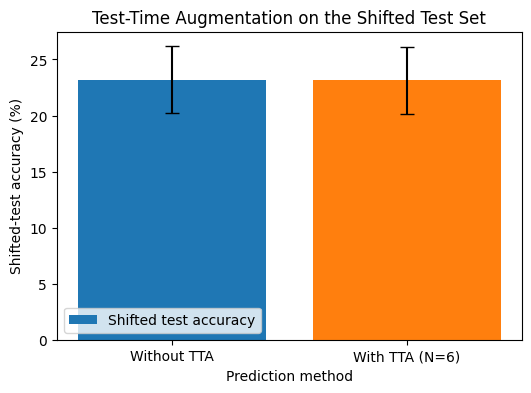

In [54]:
plt.figure(figsize=(6, 4))
plt.bar(['Without TTA', f'With TTA (N={N_TTA})'],
        [tta_scores['no_tta'].mean() * 100, tta_scores['tta'].mean() * 100],
        yerr=[tta_scores['no_tta'].std() * 100, tta_scores['tta'].std() * 100],
        capsize=5, color=['tab:blue', 'tab:orange'], label='Shifted test accuracy')
plt.xlabel("Prediction method")
plt.ylabel("Shifted-test accuracy (%)")
plt.title("Test-Time Augmentation on the Shifted Test Set")
plt.legend()
plt.show()

## Part F Conclusion
- **Accuracy:** TTA changes shifted-test accuracy from 23.20 ± 2.97% to 23.13 ± 2.96% (−0.07 points). That is no improvement; the difference is far inside the seed-to-seed spread.
- **Cost:** 6 forward passes per image; inference on 10,000 images takes 7.12 s instead of 1.07 s (about 6.7×).
- **Why it does not help:** the six views (flip and 2-pixel shifts) only vary position, and the model was already trained with flips and translations, so its predictions on these views are nearly identical and averaging them adds nothing. None of the views undoes what actually causes the errors: channel swap, brightness/contrast change, blur or the occlusion box.
- **Decision:** TTA is not used for the final score; it costs 6.7× the time for no gain.

## Final Summary
Final test score, the configuration that produced it, and the baseline for comparison.

In [55]:
f = final['scores'].mean() * 100
print("FINAL SUMMARY")
print("Final model           :", final_name)
print("Config                :", final['config'])
print("Seeds                 :", SEEDS)
print("Val accuracy          :", mean_std(final['scores'], 'val'), "%")
print("Clean-test accuracy   :", mean_std(final['scores'], 'clean'), "%")
print("Shifted-test accuracy :", mean_std(final['scores'], 'shifted'), "%")
print("Shifted-test with TTA :", mean_std(tta_scores, 'tta'), "%")
print("Baseline shifted-test :", mean_std(baseline['scores'], 'shifted'), "%")
print("Trainable parameters  :", f"{count_trainable(final['models'][0]):,}")

FINAL SUMMARY
Final model           : + Mixup + label smoothing
Config                : {'geometric': True, 'photometric': True, 'erasing': True, 'mixup': True, 'width': 1.0, 'dropout': 0.3, 'weight_decay': 0.05, 'label_smoothing': 0.1, 'lr': 0.001, 'cosine_lr': True, 'early_stopping': True}
Seeds                 : [42, 123, 2026]
Val accuracy          : 47.67 ± 2.08 %
Clean-test accuracy   : 38.06 ± 3.68 %
Shifted-test accuracy : 23.20 ± 2.97 %
Shifted-test with TTA : 23.13 ± 2.96 %
Baseline shifted-test : 18.83 ± 0.44 %
Trainable parameters  : 178,682


**Final test score:** shifted-test accuracy **23.20 ± 2.97%** (mean ± std over seeds 42, 123, 2026), clean-test 38.06 ± 3.68%, validation 47.67 ± 2.08%. Baseline for comparison: shifted 18.83 ± 0.44%, clean 43.01 ± 2.77%.

**Configuration that produced it:** Inception-style CNN with 178,682 trainable parameters (VGG-style 3×3 stem, two Inception modules with 1×1 / 3×3 / 5×5 + pool branches, Global Average Pooling, Dense(128) + Dropout 0.3, softmax), trained from scratch on 400 images for at most 60 epochs with AdamW (lr 1e-3, weight decay 0.05), cosine LR decay and early stopping on validation accuracy. On-the-fly augmentation: flip, rotation ±30°, translation, zoom, brightness / contrast / saturation jitter, blur, noise, Random Erasing, and Mixup (α = 0.2) with label smoothing 0.1. Regularization and the final configuration were selected on validation images only.

**Single change that helped most:** photometric augmentation (brightness, contrast, saturation, blur, noise). Alone it adds +2.95 points of shifted-test accuracy, the largest single gain, and together with geometric augmentation +4.32 points, which is almost the whole improvement of the final model over the baseline (+4.37).

**Limitations:** the gain on the shifted test costs 4.95 points of clean-test accuracy, because the full augmentation stack makes this small model underfit (training accuracy 45–56%). Random Erasing, Mixup and TTA gave no measurable benefit in this run, and robustness did not transfer to the hidden channel-swap corruption.

**Reproducibility:** seeds `[42, 123, 2026]` for training, `DATA_SEED = 42` for the 500-image subset and split, `SHIFT_SEED = 1234` for the shifted test set; `enable_op_determinism()` is on. The numbers above are from a Google Colab GPU run with TensorFlow 2.21; re-running in the same environment reproduces them, while a different GPU or TensorFlow version can change them slightly.